# Teste das métricas do Dashboard 2

Antes de levar as métricas para o app, calculo cada uma aqui e faço os gráficos prévios. Uso o dataset tratado (`data/clean/dataset.csv`), o mesmo que o app lê.

## Carregando os dados

Marco como hit as músicas da faixa alta de popularidade (66 a 100), que já vem na coluna `popularity_category`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path("..") if Path("../data").exists() else Path(".")
df = pd.read_csv(RAIZ / "data" / "clean" / "dataset.csv")
df["hit"] = df["popularity_category"] == "High"

## Os quatro indicadores

A função kpis calcula, para qualquer recorte: quantas músicas ele tem, a taxa de hits, a mediana de streams (a "música típica") e a parte dos streams que fica com o 1% das músicas mais ouvidas. É a mesma conta que vai para o app.

In [3]:
def kpis(d):
    streams = d["stream_count"].sort_values(ascending=False)
    top1 = max(1, int(len(streams) * 0.01))
    return pd.Series({
        "músicas": len(d),
        "taxa de hits (%)": round(100 * d["hit"].mean(), 1),
        "streams da música típica (mediana)": d["stream_count"].median(),
        "streams no 1% mais ouvido (%)": round(100 * streams.iloc[:top1].sum() / streams.sum(), 1),
    })


kpis(df)

músicas                               85000.0
taxa de hits (%)                         11.8
streams da música típica (mediana)     2000.0
streams no 1% mais ouvido (%)            73.5
dtype: float64

## Indicadores por gênero

Rodo a mesma função para cada gênero, para ver se algum se destaca. A linha tracejada do gráfico é a taxa de hits do catálogo inteiro.

,músicas,taxa de hits (%),streams da música típica (mediana),streams no 1% mais ouvido (%)
R&B,7084.0,12.5,2000.0,72.1
Pop,7096.0,12.4,2000.0,71.5
Metal,7200.0,12.1,2000.0,71.6
Country,7030.0,12.0,2000.0,74.0
Hip-Hop,7160.0,11.9,2000.0,69.5
EDM,6894.0,11.8,2000.0,76.0
Folk,7080.0,11.8,2000.0,71.7
Classical,7158.0,11.7,2000.0,71.7
Rock,7113.0,11.5,2000.0,74.6
Indie,7007.0,11.4,2000.0,74.8


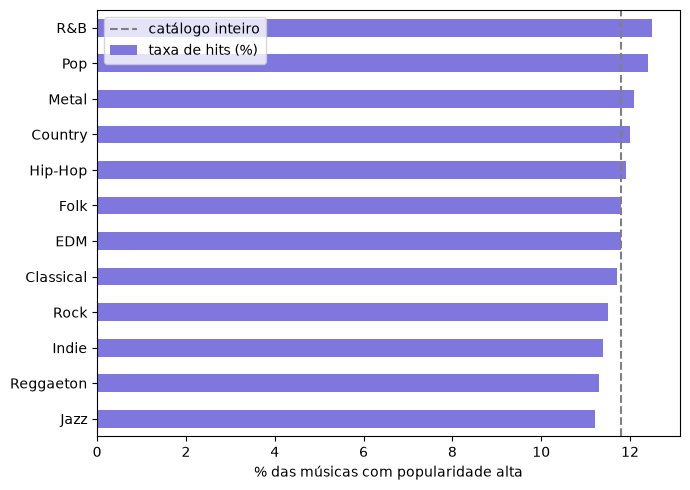

In [4]:
por_genero = pd.DataFrame({genero: kpis(d) for genero, d in df.groupby("genre")}).T
display(por_genero.sort_values("taxa de hits (%)", ascending=False))

ax = por_genero["taxa de hits (%)"].sort_values().plot(kind="barh", color="#7F77DD", figsize=(7, 5))
ax.axvline(kpis(df)["taxa de hits (%)"], color="gray", linestyle="--", label="catálogo inteiro")
ax.set_xlabel("% das músicas com popularidade alta")
ax.legend()
plt.tight_layout()
plt.show()

## Streams por faixa de popularidade

Divido a popularidade em faixas de 5 pontos e calculo a mediana de streams de cada uma. O eixo dos streams está em escala log, senão a faixa de 95 a 100 esmagaria as outras.

popularity
(-0.001, 5.0]        1000.0
(5.0, 10.0]          1000.0
(10.0, 15.0]         1000.0
(15.0, 20.0]         1000.0
(20.0, 25.0]         1000.0
(25.0, 30.0]         1000.0
(30.0, 35.0]         1000.0
(35.0, 40.0]         1000.0
(40.0, 45.0]         2000.0
(45.0, 50.0]         2000.0
(50.0, 55.0]         3000.0
(55.0, 60.0]         7000.0
(60.0, 65.0]        14000.0
(65.0, 70.0]        31000.0
(70.0, 75.0]        67000.0
(75.0, 80.0]       164000.0
(80.0, 85.0]       454500.0
(85.0, 90.0]       885500.0
(90.0, 95.0]      2364500.0
(95.0, 100.0]    14738000.0
Name: stream_count, dtype: float64

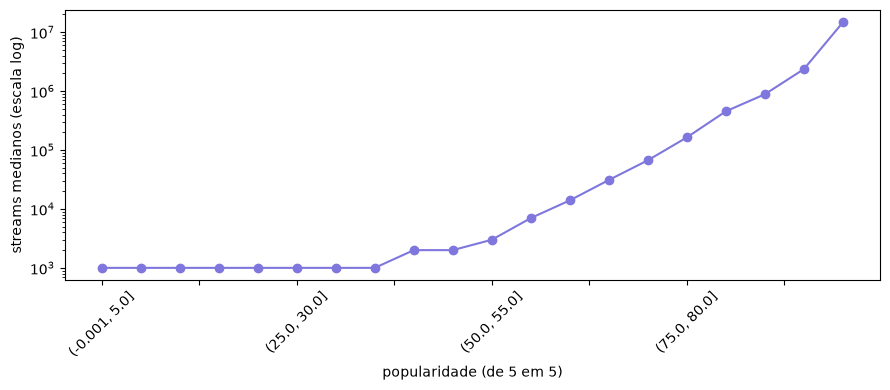

In [5]:
faixas_pop = pd.cut(df["popularity"], bins=range(0, 101, 5), include_lowest=True)
streams_por_pop = df.groupby(faixas_pop, observed=True)["stream_count"].median()
display(streams_por_pop)

ax = streams_por_pop.plot(marker="o", color="#7F77DD", logy=True, figsize=(9, 4), rot=45)
ax.set_xlabel("popularidade (de 5 em 5)")
ax.set_ylabel("streams medianos (escala log)")
plt.tight_layout()
plt.show()

## Quem fica com os streams

Comparo, para cada faixa de popularidade, a parte que ela representa no catálogo e a parte que ela fica dos streams.

,musicas,streams
popularity_category,,
Low,12.8,0.1
Medium,75.4,4.4
High,11.8,95.5


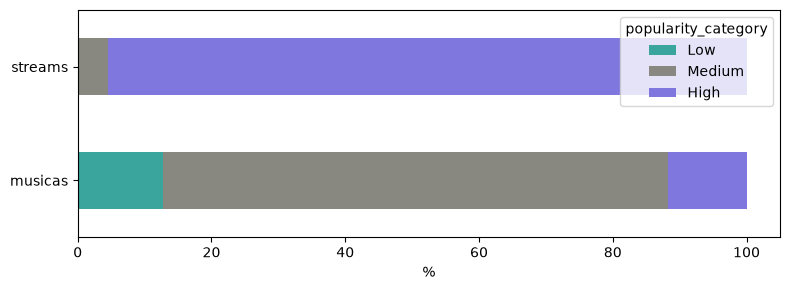

In [6]:
peso = df.groupby("popularity_category").agg(musicas=("stream_count", "size"), streams=("stream_count", "sum"))
peso = (100 * peso / peso.sum()).round(1).reindex(["Low", "Medium", "High"])
display(peso)

ax = peso.T.plot(kind="barh", stacked=True, color=["#3AA59D", "#888780", "#7F77DD"], figsize=(8, 3))
ax.set_xlabel("%")
plt.tight_layout()
plt.show()

## O que observei

- A taxa de hits é parecida em todos os gêneros, entre 11,2% e 12,5%, e a concentração também (de 69,5% a 76%). Escolher gênero não muda a chance de sucesso nesta base.
- Até uns 50 pontos de popularidade, a música típica fica entre 1 e 2 mil streams. A partir daí, cada 5 pontos rendem mais ou menos o dobro, até 14,7 milhões na faixa de 95 a 100.
- As músicas de popularidade alta são 11,8% do catálogo e ficam com 95,5% dos streams. No catálogo inteiro, 1% das músicas concentra 73,5% de todos os streams.
- Por isso as métricas do Dashboard 2 focam em quantas músicas chegam à faixa alta e em quanto o resultado depende de poucos sucessos, e não em comparar gêneros.